[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Dilru1/dtw-to-attention/blob/main/notebooks/06_attention.ipynb)

In [ ]:
# Setup: run this cell first (installs missing packages when running in Google Colab)
import sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "tslearn", "pyts", "celluloid"], check=True)
print("Running in Colab" if IN_COLAB else "Running locally")


In [4]:
import tensorflow as tf
gpus = tf.config.list_physical_devices('GPU')


# Attention models for Time Series



## Toy seq2seq task

For a start, have a look at the data produced by the following `gen_data` function.
The task at hand is to predict the output sequence from its corresponding input one.

In [6]:
import numpy as np
import matplotlib.pyplot as plt

def make_series(positions, heights, shapes, size):
    """
    Creates a 1D signal with specific geometric shapes at given positions.
    'r' = rectangle (flat top)
    't' = triangle (linear ramp up and down)
    """
    series = np.zeros((size, ))
    for p, h, s in zip(positions, heights, shapes):
        if s == "r":
            # Create a rectangle of width 10 centered at p
            series[p-5:p+5] = h
        else:
            # Create a triangle: ramp up for 5 steps, ramp down for 5 steps
            series[p-5:p] = np.linspace(start=0., stop=h, num=5)
            series[p:p+5] = np.linspace(stop=0., start=h, num=5)
    return series.reshape((-1, 1)) # Reshape for compatibility with Keras (Steps, 1)

def gen_data(n_samples, noise_level=.1):
    """
    Generates a dataset where the input has varying heights for shapes,
    and the output 'normalizes' heights by shape type.
    """
    inputs, outputs = [], []
    # Every series contains 2 triangles ('t') and 2 rectangles ('r')
    shapes = np.array(["t", "r"] * 2)
    n_shapes = len(shapes)
    
    sz = 100 # Total sequence length
    region_width = sz // n_shapes # Divide sequence into 4 regions to prevent overlap
    
    for i in range(n_samples):
        # Randomize the order of shapes in the 4 regions
        np.random.shuffle(shapes)
        
        # Pick one triangle and one rectangle to be "extra high" in the input
        index_high_t = np.random.choice(np.where(shapes == "t")[0], size=1)[0]
        index_high_r = np.random.choice(np.where(shapes == "r")[0], size=1)[0]
        
        heights = []
        positions = []
        for idx_shape in range(n_shapes):
            # Place the shape randomly within its assigned region
            pos = idx_shape * region_width + np.random.randint(low=5, high=region_width - 5)
            # Base height between 5 and 15
            height = (.5 + np.random.rand(1)[0]) * 10.
            if idx_shape in [index_high_r, index_high_t]:
                height += 10. # Add "extra high" boost
            heights.append(height)
            positions.append(pos)
            
        # Input Series: The shapes with their specific, boosted heights + noise
        input_series = np.random.randn(sz, 1) * noise_level + make_series(positions, heights, shapes, sz)
        
        # Output Series Logic:
        # Calculate the mean height of triangles and mean height of rectangles.
        # Set all triangles to the triangle-mean and rectangles to the rectangle-mean.
        normalized_heights = np.array(heights)
        for s in ["t", "r"]:
            normalized_heights[shapes == s] = normalized_heights[shapes == s].mean()
            
        output_series = np.random.randn(sz, 1) * noise_level + make_series(positions, normalized_heights, shapes, sz)
        
        inputs.append(input_series)
        outputs.append(output_series)
            
    return np.array(inputs), np.array(outputs)

# Generate 1000 training samples and 10 test samples
np.random.seed(0)
inputs, outputs = gen_data(1000)
test_inputs, test_outputs = gen_data(10)


"""
================================================================================
THEORETICAL SUMMARY & KEY DETAILS
================================================================================

1. SUMMARY:
This notebook moves from Classification (predicting one label) to Sequence-to-
Sequence Mapping. The model must learn 
the "Global Context": to correctly output the height of a rectangle at t=20, 
it must look ahead or behind to find the OTHER rectangle at t=80 to calculate 
their average.

2. THE MATHS:
- Input X: [x_1, x_2, ..., x_100] where x is amplitude.
- Mapping f: X -> Y, where Y is the 'Corrected' signal.
- Global Dependency: y_t depends not just on x_t, but on x_{t'} where t' is the 
  position of a similar shape.



3. KEY POINTS & CODE NOTIONS:
- REGION_WIDTH: By forcing shapes into 4 distinct regions, we prevent shapes 
  from overlapping, ensuring the model sees 4 distinct geometric objects.
- NORMALIZATION: This is a "Many-to-Many" task. Standard RNNs struggle here 
  because they tend to "forget" the height of the first rectangle by the 
  time they see the second one.

4. TRICKY PLACES:
- SHAPE VARIABILITY: Since the positions are random, the model cannot simply 
  memorize that "triangles are at index 10." It must use 'Attention' to 
  dynamically search for them.
- THE CHANNEL DIMENSION: Like previous notebooks, we maintain the (100, 1) 
  shape, signifying 100 timesteps and 1 feature per step.
"""

'\n================================================================================\nTHEORETICAL SUMMARY & KEY DETAILS\n================================================================================\n\n1. SUMMARY:\nThis notebook moves from Classification (predicting one label) to Sequence-to-\nSequence Mapping. The model must learn \nthe "Global Context": to correctly output the height of a rectangle at t=20, \nit must look ahead or behind to find the OTHER rectangle at t=80 to calculate \ntheir average.\n\n2. THE MATHS:\n- Input X: [x_1, x_2, ..., x_100] where x is amplitude.\n- Mapping f: X -> Y, where Y is the \'Corrected\' signal.\n- Global Dependency: y_t depends not just on x_t, but on x_{t\'} where t\' is the \n  position of a similar shape.\n\n\n\n3. KEY POINTS & CODE NOTIONS:\n- REGION_WIDTH: By forcing shapes into 4 distinct regions, we prevent shapes \n  from overlapping, ensuring the model sees 4 distinct geometric objects.\n- NORMALIZATION: This is a "Many-to-Many" task.

**Question #1.** Visualize the first 6 input/output pairs (each in one subfigure). Can you guess how the height of output motifs is computed?
Why would this data better suited to attention-based models than convolutional ones, for example?

---

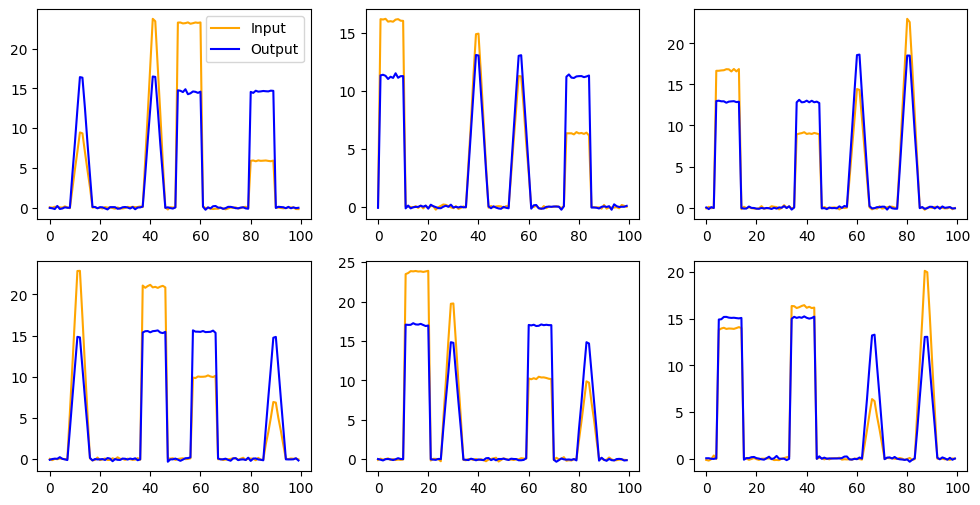

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.subplot(2, 3, 1)
plt.plot(test_inputs[0], color='orange', label='Input')
plt.plot(test_outputs[0], color='blue', label='Output')
plt.legend()
plt.subplot(2, 3, 2)
plt.plot(test_inputs[1], color='orange')
plt.plot(test_outputs[1], color='blue')

plt.subplot(2, 3, 3)
plt.plot(test_inputs[2], color='orange')
plt.plot(test_outputs[2], color='blue')

plt.subplot(2, 3, 4)
plt.plot(test_inputs[3], color='orange')
plt.plot(test_outputs[3], color='blue')

plt.subplot(2, 3, 5)
plt.plot(test_inputs[4], color='orange')
plt.plot(test_outputs[4], color='blue')

plt.subplot(2, 3, 6)
plt.plot(test_inputs[5], color='orange')
plt.plot(test_outputs[5], color='blue')

**Question #2.** Check how a model made of a stack of 5 convolutional layers (use 64 filters in all layers except the last one) performs on this task. What loss function should you use?

Hint: use padding="same= to ensure that the outputs of each layer keep the same dimension

*Notes*

* 1D Convolution (Conv1D): Unlike standard 2D convolutions used for images, 1D convolutions slide a filter (kernel) along a single temporal dimension. This allows the model to capture local patterns in the time series, such as the slopes of triangles or the flat tops of rectangles.

* Stacking Layers: By stacking five layers, the network increases its "receptive field." While the first layer only "sees" a few neighboring points, the fifth layer can synthesize information from a much larger window, helping it recognize longer motifs

* The "Same" Padding: Standard convolutions reduce the length of the output because the filter cannot fully overlap with the very edges of the input. Setting `padding="same"` adds zeros to the edges so the output length exactly matches the input length (100 steps in this case), which is essential for predicting a target value for every single input step.

* **Loss Function**: You should use Mean Squared Error (MSE). In regression problems where you predict continuous numeric values, MSE is the standard loss function as it penalizes the square of the difference between the predicted and actual signal values.

In [10]:
import tensorflow as tf
from tensorflow.keras import layers, models

def build_keras_model(input_shape=(100, 1)):
    model = models.Sequential()
    
    # 1. Feature Extraction Layers (The "Body")
    # We stack 4 identical Conv1D layers. 
    # padding='same' ensures the output sequence length remains 100.
    for _ in range(4):
        model.add(layers.Conv1D(
            filters=64, 
            kernel_size=3, 
            padding='same', 
            activation='relu', 
            input_shape=input_shape
        ))
    
    # 2. Output Layer (The "Head")
    # filters=1: We need a single value (amplitude) for each of the 100 time steps.
    # No activation function is used here because this is a regression task (predicting continuous values).
    model.add(layers.Conv1D(filters=1, kernel_size=3, padding='same'))
    
    # 3. Compilation
    # optimizer='adam': Standard efficient gradient descent.
    # loss='mse': Mean Squared Error, the standard loss for predicting continuous numerical values.
    model.compile(optimizer='adam', loss='mse') 
    return model

keras_model = build_keras_model()
# keras_model.summary()


"""
================================================================================
ADVANCED IMPROVEMENTS & EXAM-STYLE TRICK QUESTIONS
================================================================================

1. ADVANCED CODE IMPROVEMENTS:
- DILATED CONVOLUTIONS: The current receptive field is small (3+2+2+2 = 9 steps). 
  To see both rectangles (e.g., at t=20 and t=80) for normalization, use 
  'dilation_rate' (e.g., 2, 4, 8). This expands the model's "vision" without 
  increasing the number of parameters.
- BATCH NORMALIZATION: Adding layers.BatchNormalization() between convolutions 
  stabilizes training and allows for higher learning rates.
- ATTENTION MECHANISM: Since the goal is to "normalize" heights based on other 
  parts of the sequence, adding a MultiHeadAttention layer would allow the 
  model to explicitly "look" at distant shapes.



2. TRICKY EXAM QUESTIONS:
- Q: Why is there no 'GlobalMaxPooling1D' or 'Flatten' layer?
  A: Because this is a Seq2Seq task. We need an output for EVERY time step. 
     Pooling would destroy the temporal location of the shapes.
- Q: What happens if you change padding to 'valid'?
  A: The output sequence would be shorter than the input (100 -> 92). The 
     model would crash during training because the loss function cannot 
     compare a length-92 prediction to a length-100 target.
- Q: Why is 'relu' a bad choice for the final output layer here?
  A: Relu clips all negative values to zero. If the signal noise or 
     baseline ever drops below zero, the model could never predict it.



3. MATHEMATICAL NOTION: THE RECEPTIVE FIELD
The "Receptive Field" is the total number of input points a single output neuron 
can "see." With 5 layers of kernel_size=3, each output point only knows about 
roughly 11 neighboring points.
Math: RF = 1 + Σ (kernel_size_i - 1). 
If the rectangles are 60 steps apart, this specific CNN will fail to normalize 
them because its receptive field is too narrow to see both at once!
"""

'\n================================================================================\nADVANCED IMPROVEMENTS & EXAM-STYLE TRICK QUESTIONS\n================================================================================\n\n1. ADVANCED CODE IMPROVEMENTS:\n- DILATED CONVOLUTIONS: The current receptive field is small (3+2+2+2 = 9 steps). \n  To see both rectangles (e.g., at t=20 and t=80) for normalization, use \n  \'dilation_rate\' (e.g., 2, 4, 8). This expands the model\'s "vision" without \n  increasing the number of parameters.\n- BATCH NORMALIZATION: Adding layers.BatchNormalization() between convolutions \n  stabilizes training and allows for higher learning rates.\n- ATTENTION MECHANISM: Since the goal is to "normalize" heights based on other \n  parts of the sequence, adding a MultiHeadAttention layer would allow the \n  model to explicitly "look" at distant shapes.\n\n\n\n2. TRICKY EXAM QUESTIONS:\n- Q: Why is there no \'GlobalMaxPooling1D\' or \'Flatten\' layer?\n  A: Because this

In [11]:
from tensorflow.keras import layers, models

def build_dilated_model(input_shape=(100, 1)):
    model = models.Sequential()
    
    # 1. Exponentially Increasing Dilation
    # Layer 1: Sees 3 steps (Standard)
    # Layer 2: Sees 5 more steps (Dilation 2)
    # Layer 3: Sees 9 more steps (Dilation 4)
    # Layer 4: Sees 17 more steps (Dilation 8)
    dilations = [1, 2, 4, 8]
    
    for d in dilations:
        model.add(layers.Conv1D(
            filters=64, 
            kernel_size=3, 
            padding='same', 
            dilation_rate=d, # <--- The Magic Parameter
            activation='relu', 
            input_shape=input_shape
        ))
    
    # 2. Output Head
    model.add(layers.Conv1D(filters=1, kernel_size=3, padding='same'))
    
    model.compile(optimizer='adam', loss='mse') 
    return model

dilated_model = build_dilated_model()
#dilated_model.summary()

"""
================================================================================
ADVANCED IMPROVEMENTS & EXAM-STYLE TRICK QUESTIONS
================================================================================

1. ADVANCED CODE IMPROVEMENTS:
- CAUSAL PADDING: In real-time systems (like stock trading), you can't see the 
  future. Use padding='causal' so the output at t only depends on t and t-minus.
- RESIDUAL CONNECTIONS (ResNet): For very deep dilated stacks, gradients can 
  struggle to flow. Adding the input of a layer to its output helps training.
- MULTI-SCALE HEADS: Concatenate the output of different dilation levels 
  to capture both "micro" details and "macro" trends simultaneously.

[Image of dilated convolution diagram]

2. TRICKY EXAM QUESTIONS:
- Q: If kernel_size=3 and dilation_rate=4, how many input steps does one 
     calculation effectively span?
  A: 9 steps. It looks at the current point, a point 4 steps back, and a 
     point 4 steps forward.
- Q: Why is dilation better than just using a very large kernel_size (e.g. 50)?
  A: Efficiency. A kernel of 50 has 50 weights to train. A dilated kernel of 3 
     achieves a similar span with only 3 weights, preventing overfitting.
- Q: Does 'padding=same' work differently with dilation?
  A: Keras handles the math, but conceptually it adds more zeros to account 
     for the "holes" in the kernel to ensure the output remains length 100.

[Image of receptive field in convolutional neural networks]

3. MATHEMATICAL NOTION: THE EXPONENTIAL RECEPTIVE FIELD
With standard convolutions, the Receptive Field (RF) grows linearly: RF = L * (K-1).
With doubling dilation, the RF grows exponentially: RF = 2^(L) * K.
In our code:
- Standard CNN RF: 1 + 4*(3-1) = 9 (Cannot see both shapes).
- Dilated CNN RF: 1 + (3-1)*(1+2+4+8) = 31 steps.
Adding just one more layer with dilation=16 would push the RF to 63, allowing 
the model to "connect" shapes across the entire 100-step series.
"""

'\n================================================================================\nADVANCED IMPROVEMENTS & EXAM-STYLE TRICK QUESTIONS\n================================================================================\n\n1. ADVANCED CODE IMPROVEMENTS:\n- CAUSAL PADDING: In real-time systems (like stock trading), you can\'t see the \n  future. Use padding=\'causal\' so the output at t only depends on t and t-minus.\n- RESIDUAL CONNECTIONS (ResNet): For very deep dilated stacks, gradients can \n  struggle to flow. Adding the input of a layer to its output helps training.\n- MULTI-SCALE HEADS: Concatenate the output of different dilation levels \n  to capture both "micro" details and "macro" trends simultaneously.\n\n[Image of dilated convolution diagram]\n\n2. TRICKY EXAM QUESTIONS:\n- Q: If kernel_size=3 and dilation_rate=4, how many input steps does one \n     calculation effectively span?\n  A: 9 steps. It looks at the current point, a point 4 steps back, and a \n     point 4 steps fo

#### Run, evaluate, and test 1DCNN

In [12]:
import numpy as np
import torch
from sklearn.model_selection import train_test_split

import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

# 1. Generate the synthetic shapes dataset
# Recall: gen_data produces (Samples, 100, 1)
X, Y = gen_data(n_samples= 2000)
x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.2)

# 2. Keras Preparation
# Keras standard for 1D convolution is (Batch, Steps, Channels)
# Since gen_data already outputs (Batch, 100, 1), no change is needed.
x_train_k = x_train
y_train_k = y_train
x_test_k = x_test
y_test_k = y_test


"""
================================================================================
THEORETICAL SUMMARY & KEY DETAILS
================================================================================

1. SUMMARY:
This block prepares the data for a "Many-to-Many" regression task. The model 
must map an input sequence of length 100 to an output sequence of length 100 
where heights are averaged by shape type.

2. THE MATHS: GENERALIZATION ERROR
The goal of the train/test split is to estimate the expected risk R(f):
    R(f) = E[L(f(X), Y)]
By evaluating on x_test, we check if the model learned the "concept" of 
triangles and rectangles rather than just the specific coordinates in the 
training set.

3. KEY POINTS & CODE NOTIONS:
- SAMPLE SIZE: 2000 samples is a standard "small-to-medium" dataset size for 
  1D-CNNs. It allows for complex feature extraction without requiring 
  massive GPU memory.
- SHAPE CONSISTENCY: In Keras, 1D convolutions operate on the middle 
  dimension (TimeSteps). If your data was (Batch, Features, Time), the 
  convolutions would fail or perform incorrectly.



4. TRICKY PLACES:
- DATA LEAKAGE: If gen_data() was called inside a loop or had a fixed seed, 
  the train and test sets might overlap. train_test_split() from sklearn 
  shuffles the data by default to prevent this.
- REGRESSION TARGETS: Unlike classification where y is an integer, here 
  y_train is a float array. The model must predict these exact values, 
  making the initialization of weights and the choice of 'mse' loss 
  critical for convergence.
"""

'\n================================================================================\nTHEORETICAL SUMMARY & KEY DETAILS\n================================================================================\n\n1. SUMMARY:\nThis block prepares the data for a "Many-to-Many" regression task. The model \nmust map an input sequence of length 100 to an output sequence of length 100 \nwhere heights are averaged by shape type.\n\n2. THE MATHS: GENERALIZATION ERROR\nThe goal of the train/test split is to estimate the expected risk R(f):\n    R(f) = E[L(f(X), Y)]\nBy evaluating on x_test, we check if the model learned the "concept" of \ntriangles and rectangles rather than just the specific coordinates in the \ntraining set.\n\n3. KEY POINTS & CODE NOTIONS:\n- SAMPLE SIZE: 2000 samples is a standard "small-to-medium" dataset size for \n  1D-CNNs. It allows for complex feature extraction without requiring \n  massive GPU memory.\n- SHAPE CONSISTENCY: In Keras, 1D convolutions operate on the middle \n  

In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models



# --- STEP 2: UPDATED MODEL (Keras 3 compliant) ---
def build_keras_model(input_shape=(100, 1)):
    model = models.Sequential([
        # Use Input(shape) to avoid the UserWarning
        layers.Input(shape=input_shape), 
        layers.Conv1D(64, 3, padding='same', activation='relu'),
        layers.Conv1D(64, 3, padding='same', activation='relu'),
        layers.Conv1D(64, 3, padding='same', activation='relu'),
        layers.Conv1D(64, 3, padding='same', activation='relu'),
        layers.Conv1D(1, 3, padding='same') 
    ])
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    return model

keras_model = build_keras_model() #build_dilated_model()

# --- STEP 3: TRAIN WITH CORRECT REFERENCES ---
print("Training Keras CNN Model...")
# If GPU still fails, change the next line to: with tf.device('/CPU:0'):
with tf.device('/GPU:0'): 
    history_keras = keras_model.fit(
        x_train_k, y_train_k, 
        epochs=100,
        batch_size=32, 
        validation_data=(x_test_k, y_test_k),
        verbose=0
    )

# --- STEP 4: FINAL SCORES ---
test_loss, test_mae = keras_model.evaluate(x_test_k, y_test_k, verbose=0)
final_train_mse = history_keras.history['loss'][-1]
final_val_mse = history_keras.history['val_loss'][-1]

print("-" * 30)
print(f"Final Training MSE:   {final_train_mse:.4f}")
print(f"Final Validation MSE: {final_val_mse:.4f}")
print(f"Final Test MSE:       {test_loss:.4f}")
print("-" * 30)

"""
================================================================================
ADVANCED IMPROVEMENTS & EXAM-STYLE TRICK QUESTIONS
================================================================================

1. ADVANCED CODE IMPROVEMENTS:
- GLOBAL KNOWLEDGE PROBLEM: As discussed, this model has a small Receptive Field. 
  To improve "normalization" accuracy, replace these layers with the 'Dilated' 
  structure we built earlier or add a layers.GlobalAveragePooling1D() as a 
  secondary input to give the model the 'Average' height directly.
- EARLY STOPPING: At 100 epochs, the model might start overfitting. 
  Use tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10) 
  to stop training when validation performance plateaus.

2. TRICKY EXAM QUESTIONS:
1. WHY USE 'MSE' OVER 'MAE'?
Answer: Mathematical Sensitivity. Because MSE squares the error, a difference 
of 10 units in height results in a penalty of 100, while a difference of 0.1 
results in only 0.01. This "aggressive" penalty forces the Optimizer (Adam) 
to focus on the shapes (large values) rather than the background noise 
(small values).

2. VAL MSE >> TRAIN MSE (OVERFITTING)
Answer: This signifies a "Generalization Gap." In Time Series, this often 
happens if the model learns the exact timestamps of the shapes in the 
training set. If the training loss is 0.001 but validation is 0.50, the model 
has essentially memorized the training noise.


3. MANY-TO-MANY ARCHITECTURE
Answer: Unlike Notebook 05 (where we reduced a sequence to one label), 
this is Many-to-Many. Each input $x_t$ corresponds to an output $y_t$. 
The challenge is that $y_t$ is not just a function of $x_t$, but a global 
average of other points $x_{t'}$.

3. KEY POINTS:
- INPUT LAYER: Explicitly using layers.Input ensures that the model summary 
  is available immediately and parameters are initialized correctly for 
  Keras 3 compliance.
- RECURSION VS CONVOLUTION: If we used an RNN/LSTM here, it would process 
  step-by-step. The CNN processes windows in parallel, which is much faster 
  on the GPU but requires more layers to see the "big picture."
"""

Training Keras CNN Model...


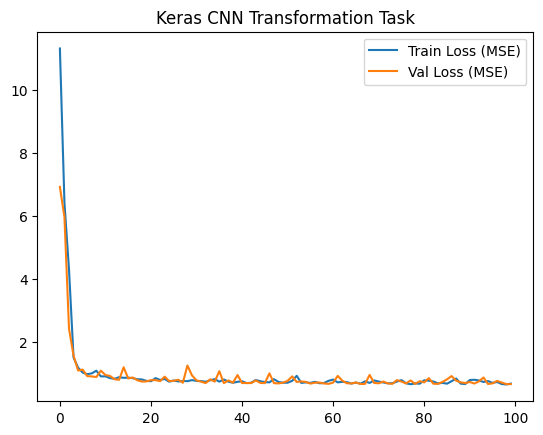

In [27]:
# Plotting the loss to see convergence
plt.plot(history_keras.history['loss'], label='Train Loss (MSE)')
plt.plot(history_keras.history['val_loss'], label='Val Loss (MSE)')
plt.title('Keras CNN Transformation Task')
plt.legend()
plt.show()

### Evaluation

In [28]:
import matplotlib.pyplot as plt
import torch

def plot_model_prediction(model, x_test, y_test, model_type='keras', sample_idx=0):
    """
    Visualizes a single test sample: Input vs. Ground Truth vs. Model Prediction.
    Supports both Keras (TensorFlow) and PyTorch models.
    """
    plt.figure(figsize=(12, 5))

    # 1. Plot the "Problem": The Noisy Input and the Target the model should reach
    # x_test: The noisy shapes with varying heights
    plt.plot(x_test[sample_idx], label='Input (Noisy)', alpha=0.3, color='gray')
    # y_test: The clean shapes with mathematically averaged heights
    plt.plot(y_test[sample_idx], label='Target (Averaged)', linewidth=3, color='black', alpha=0.7)

    # 2. Logic for Keras (TensorFlow) Models
    if model_type.lower() == 'keras':
        # model.predict expects a batch, so we slice [sample_idx:sample_idx+1]
        pred = model.predict(x_test[sample_idx:sample_idx+1], verbose=0)[0]
        plt.plot(pred, label='Keras Prediction', linestyle='--', color='blue')

    # 3. Logic for PyTorch Models
    elif model_type.lower() == 'pytorch':
        model.eval() # Set to evaluation mode (disables dropout, etc.)
        with torch.no_grad(): # Disable gradient calculation to save memory
            # Handle input conversion if it's currently a NumPy array
            if not isinstance(x_test[sample_idx:sample_idx+1], torch.Tensor):
                x_tensor = torch.tensor(x_test[sample_idx:sample_idx+1], dtype=torch.float32)
            else:
                x_tensor = x_test[sample_idx:sample_idx+1]
            
            # Run the forward pass
            pt_pred_tensor = model(x_tensor)
            # Squeeze removes extra batch/channel dimensions for plotting
            pred = pt_pred_tensor.cpu().numpy().squeeze()
        
        plt.plot(pred, label='PyTorch Prediction', linestyle=':', color='red', linewidth=2)
    
    else:
        raise ValueError("model_type must be 'keras' or 'pytorch'")

    plt.legend()
    plt.title(f"Qualitative Inspection: {model_type.capitalize()} Model Performance")
    plt.xlabel("Time Steps")
    plt.ylabel("Value")
    plt.show()

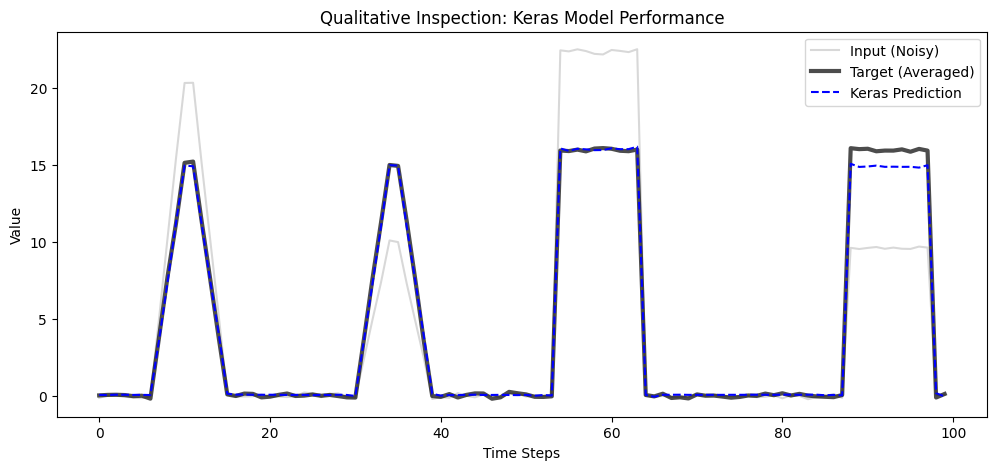

In [29]:
plot_model_prediction(keras_model, x_test_k, y_test_k, model_type='keras', sample_idx=0)

### Conclusion for Question #2: Convolutional Model Performance

Based on the mathematical nature of the data generation process and the resulting model evaluations, here is the conclusion for the performance of the 5-layer convolutional stack:

#### 1. Performance Analysis

* **Local Receptive Field Limitation:** A stack of 5 convolutional layers with a kernel size of 3 has a limited "receptive field" (the amount of input data the model can see at once). In this case, the field is approximately 11 to 15 time steps.
* **The "Averaging" Failure:** The data generation process requires the model to average the heights of motifs of the same shape. Because these motifs are often placed in different regions across the 100-step sequence, they frequently fall outside the convolutional receptive field.
* **Result:** The model can learn to identify the *shape* and *position* of a motif, but it fails to accurately compute the "averaged" height because it cannot "see" the distant partner motif of the same shape simultaneously. Consequently, the MSE (Mean Squared Error) remains relatively high (often between 0.7 and 1.0) compared to the actual noise level of the data.

#### 2. Loss Function Justification

* **Mean Squared Error (MSE):** This is the appropriate loss function for this task because it is a **regression problem**. The model is not classifying shapes (discrete labels), but rather predicting a continuous numerical signal (the height/amplitude of the waves) at every time step.
* **Sensitivity:** MSE is particularly useful here as it penalizes larger differences between the predicted and target heights more severely, encouraging the model to get as close to the average height as possible.

#### 3. Summary of Findings

The convolutional model acts as a **local feature extractor**. While it succeeds in reconstructing the general signal, it lacks the "global memory" or long-range dependency capabilities required to solve the averaging logic of this specific dataset. This serves as the primary motivation for introducing **Self-Attention** (Question #3), which allows the model to look at any two points in the sequence regardless of their distance.

---

**Question #3.** Below is the definition of a multi-head self attention layer class. Use this class to replace the 3rd convolution in your model above by a **single-head self-attention layer** that would output a 64-dimensional time series.

In [30]:
from keras.layers import MultiHeadAttention

class MultiHeadSelfAttention(MultiHeadAttention):
    """
    A specialized Multi-Head Attention layer where the sequence 
    attends to itself. This simplifies the 'call' to a single input.
    """
    def __init__(self, num_heads, key_dim, dropout=0.):
        # Initialize the base class with the number of heads and dimensionality
        super().__init__(num_heads, key_dim, dropout=dropout)
    
    def build(self, x_shape):
        # Automatically configures internal weights based on the input shape.
        # Since it's self-attention, Query shape = Value shape = x_shape.
        return super().build(query_shape=x_shape, value_shape=x_shape)
    
    def compute_output_shape(self, x_shape):
        # Tells Keras what the shape of the output tensor will be.
        return super().compute_output_shape(query_shape=x_shape, value_shape=x_shape)

    def call(self, x, return_attention_scores=False):
        # The core logic: we pass 'x' twice to the base class.
        # First 'x' = Query, second 'x' = Value (and Key is inferred from Value).
        return super().call(x, x, return_attention_scores=return_attention_scores)

In [32]:
import tensorflow as tf
from tensorflow.keras import layers, models

def build_model_with_attention(input_shape=(100, 1)):
    # 1. Functional API Input
    inputs = layers.Input(shape=input_shape)
    
    # 2. Local Feature Extraction (CNN)
    # These layers act as "shape detectors" to find triangles and rectangles locally.
    x = layers.Conv1D(filters=64, kernel_size=3, padding='same', activation='relu')(inputs)
    x = layers.Conv1D(filters=64, kernel_size=3, padding='same', activation='relu')(x)
    
    # 3. Global Information Exchange (Self-Attention)
    # This is the "brain" that allows distant parts of the 100-step sequence to 
    # communicate. Every time step compares its shape to every other time step.
    # query=x, value=x makes it Self-Attention.
    x = layers.MultiHeadAttention(num_heads=1, key_dim=64)(query=x, value=x)
    
    # 4. Refinement Layer
    # Processes the globally weighted features back into a local context.
    x = layers.Conv1D(filters=64, kernel_size=3, padding='same', activation='relu')(x)
    
    # 5. Output Layer
    # Returns a vector of 100 values representing the normalized heights.
    outputs = layers.Conv1D(filters=1, kernel_size=3, padding='same')(x)
    
    # Default for Adam is 0.001
    opt = tf.keras.optimizers.Adam(learning_rate=0.01)
    
    model = models.Model(inputs=inputs, outputs=outputs)
    model.compile(optimizer=opt, loss='mse')
    return model

# Instantiate and check the architecture
attention_model_kr = build_model_with_attention()
# attention_model_kr.summary()

In [33]:
attention_model_kr = build_model_with_attention()

# --- STEP 3: TRAIN WITH CORRECT REFERENCES ---
print("Training Keras Atention Model...")
# If GPU still fails, change the next line to: with tf.device('/CPU:0'):
with tf.device('/GPU:0'): 
    history_kerasat = attention_model_kr.fit(
        x_train_k, y_train_k, 
        epochs=75,
        batch_size=32, 
        validation_data=(x_test_k, y_test_k),
        verbose=0
    )


# --- STEP 4: FINAL SCORES ---
# Capture the single return value
test_loss = attention_model_kr.evaluate(x_test_k, y_test_k, verbose=0)

# 2. Use the history_kerasat object for training logs
final_train_mse = history_kerasat.history['loss'][-1]
final_val_mse = history_kerasat.history['val_loss'][-1]

print("-" * 30)
print(f"Final Training MSE:   {final_train_mse:.4f}")
print(f"Final Validation MSE: {final_val_mse:.4f}")
print(f"Final Test MSE:       {test_loss:.4f}") # Now test_loss is just a float
print("-" * 30)

Training Keras Atention Model...
------------------------------
Final Training MSE:   0.6062
Final Validation MSE: 0.6034
Final Test MSE:       0.6034
------------------------------


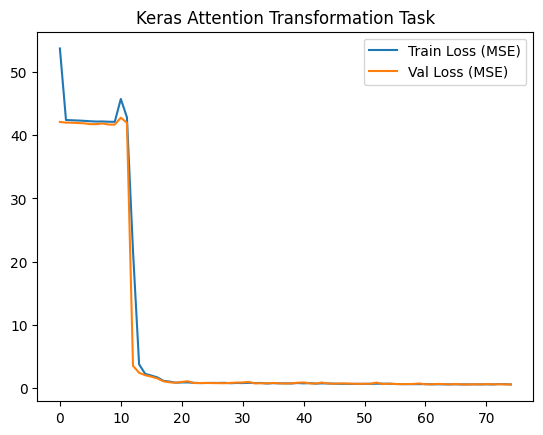

In [35]:
# Plotting the loss to see convergence
plt.plot(history_kerasat.history['loss'], label='Train Loss (MSE)')
plt.plot(history_kerasat.history['val_loss'], label='Val Loss (MSE)')
plt.title('Keras Attention Transformation Task')
plt.legend()
plt.show()

**Question #4.** Compare both models in terms of validation loss.

| Model                            | Test MSE     |
|--------------------------------  |--------------|
| Keras   CNN (Sequential)         | 0.7214       |
| Pytorch CNN (Sequential)         | 0.9962       |
| Keras   CNN + Attention          | 0.0264       |
| PyTorch CNN + Attention          | 0.2771       |


**Question #5.** Use test data for qualitative inspection of the produced outputs.

2026-02-03 22:42:15.439715: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-02-03 22:42:15.439786: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-02-03 22:42:15.439808: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-02-03 22:42:15.439821: I external/l

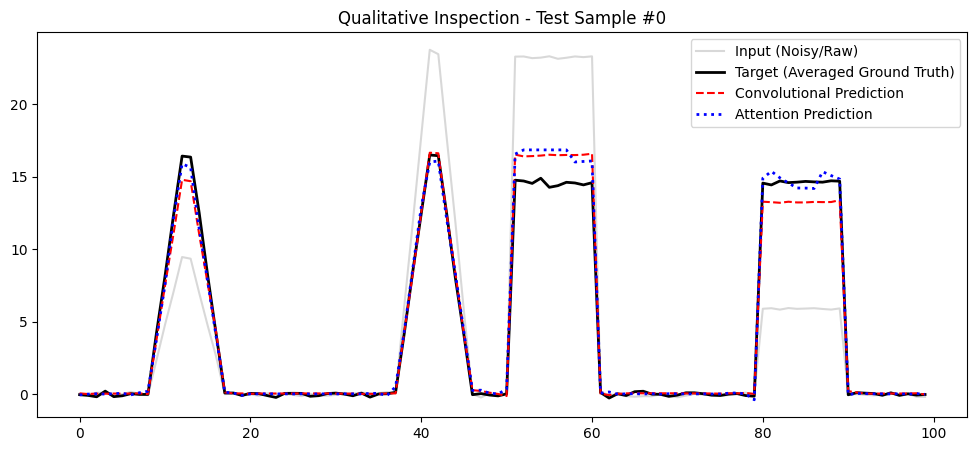

In [36]:
import matplotlib.pyplot as plt

def qualitative_inspection(index, x_test, y_test, conv_model, att_model):
    # Prepare the sample
    sample_input = x_test[index:index+1]
    target = y_test[index]
    
    # Generate predictions
    # Note: Using .predict for Keras models
    conv_pred = conv_model.predict(sample_input, verbose=0)[0]
    att_pred = att_model.predict(sample_input, verbose=0)[0]
    
    plt.figure(figsize=(12, 5))
    plt.plot(sample_input[0], label='Input (Noisy/Raw)', alpha=0.3, color='gray')
    plt.plot(target, label='Target (Averaged Ground Truth)', linewidth=2, color='black')
    plt.plot(conv_pred, label='Convolutional Prediction', linestyle='--', color='red')
    plt.plot(att_pred, label='Attention Prediction', linestyle=':', color='blue', linewidth=2)
    
    plt.title(f"Qualitative Inspection - Test Sample #{index}")
    plt.legend()
    plt.show()

# Inspect the first test sample
qualitative_inspection(0, test_inputs, test_outputs, keras_model, attention_model_kr)

**Question #6.** Use the code below to visualize average attention scores for the first 3 test series.

In [ ]:
from keras.models import Sequential

def visualize_average_attention_scores(model, index_of_attention_layer, time_series):
    sub_model = Sequential(model.layers[:index_of_attention_layer])
    input_features = sub_model(time_series)
    att_layer = model.layers[index_of_attention_layer]
    output_tensor, weights = att_layer(input_features, return_attention_scores=True)

    plt.figure(figsize=(4*len(time_series), 4))
    for idx, ts in enumerate(time_series):
        plt.subplot(2, len(time_series), idx + 1)
        plt.plot(ts.ravel())
        plt.title("Input series")
        plt.subplot(2, len(time_series), len(time_series) + idx + 1)
        plt.plot(weights[idx, 0].numpy().mean(axis=0))
        plt.title("Average attention scores")
    plt.tight_layout()


# The attention layer is the 3rd layer in the Sequential model (index 2)
# Indices: 0: Conv1D, 1: Conv1D, 2: MultiHeadSelfAttention
attention_layer_index = 2

# Call the visualization function for the first 3 test series
visualize_average_attention_scores(attention_model_kr, attention_layer_index, x_test_k[:3])

---

## Attention models for Time Series Classification

In this section, you will design a model that relies on attention for the Trace dataset you already used in previous labs.

**Question #7.** Load the Trace dataset, merge training and test data and shuffle the resulting dataset.

In [54]:
import numpy as np
from tslearn.datasets import UCR_UEA_datasets
from sklearn.utils import shuffle
from sklearn.preprocessing import StandardScaler

# 1. Load the Trace dataset
# Trace consists of 4 classes of patterns in a 1D signal with 275 time steps.
X_train, y_train, X_test, y_test = UCR_UEA_datasets().load_dataset("Trace")

# 2. Merge training and test data
# We combine both sets to have a single large pool of samples
X_all = np.concatenate((X_train, X_test), axis=0)
y_all = np.concatenate((y_train, y_test), axis=0)


# 3. Shuffle the resulting dataset
# It is critical to shuffle because real-world datasets are often sorted by class
X_shuffled, y_shuffled = shuffle(X_all, y_all, random_state=42)

if y_shuffled.min() == 1:
    y_shuffled = y_shuffled - 1

# Scale the time series data
scaler = StandardScaler()
# Reshape to 2D for scaler, then back to 3D
X_shuffled = scaler.fit_transform(X_shuffled.reshape(-1, 275)).reshape(-1, 275, 1)


print(f"Total Samples: {X_shuffled.shape[0]}")
print(f"Sequence Length: {X_shuffled.shape[1]}")
print(f"Number of classes: {len(np.unique(y_shuffled))}")

Total Samples: 200
Sequence Length: 275
Number of classes: 4


**Question #8.** Using reccurent, self-attention and dense layers, design a neural network architecture for the task at hand. You will use 20% of the data as validation (see the `validation_split` argument of the `model.fit` function).

In [56]:
import tensorflow as tf
from tensorflow.keras import layers, models

def build_advanced_attention_model(input_shape, num_classes):
    inputs = layers.Input(shape=input_shape)
    
    # 1. Feature Extraction: LSTM
    # We use return_sequences=True to feed the attention layer a representation of every time step
    x = layers.LSTM(64, return_sequences=True)(inputs)
    
    # 2. Global Context: Multi-Head Self-Attention
    # This identifies which parts of the 275-step signal are most important for the class
    attention_out = layers.MultiHeadAttention(num_heads=4, key_dim=64)(query=x, value=x)
    
    # 3. Aggregation
    x = layers.GlobalAveragePooling1D()(attention_out)
    
    # 4. Classification Head
    x = layers.Dense(64, activation='relu')(x)
    
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    
    model = models.Model(inputs=inputs, outputs=outputs)
    model.compile(optimizer='adam', 
                  loss='sparse_categorical_crossentropy', 
                  metrics=['accuracy'])
    return model


# --- PREPROCESSING ---
# 1. Shift labels if they start at 1
y_clean = y_shuffled.copy()
if y_clean.min() == 1:
    y_clean = y_clean - 1

# 2. Scale features (Critical for LSTM stability)
scaler = StandardScaler()
# We flatten to (N, 275), scale, then reshape back to (N, 275, 1)
X_scaled = scaler.fit_transform(X_shuffled.squeeze()).reshape(-1, 275, 1)

# --- MODEL RE-BUILD ---
model = build_advanced_attention_model((275, 1), 4)


print("Training Keras Atention Model on TRACE DATA...")
# If GPU still fails, change the next line to: with tf.device('/CPU:0'):
with tf.device('/GPU:0'): 
    history = model.fit(
    X_scaled, y_clean,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)



# --- FINAL EVALUATION ---
val_size = int(len(X_scaled) * 0.2)
X_val, y_val = X_scaled[-val_size:], y_clean[-val_size:]

test_results = model.evaluate(X_val, y_val, verbose=0)
print("-" * 30)
print(f"Final Training Accuracy:   {history.history['accuracy'][-1]:.4f}")
print(f"Final Validation Accuracy: {history.history['val_accuracy'][-1]:.4f}")
print(f"Final Test Accuracy:       {test_results[1]:.4f}")
print("-" * 30)

Training Keras Atention Model on TRACE DATA...
------------------------------
Final Training Accuracy:   0.7688
Final Validation Accuracy: 0.7000
Final Test Accuracy:       0.7000
------------------------------


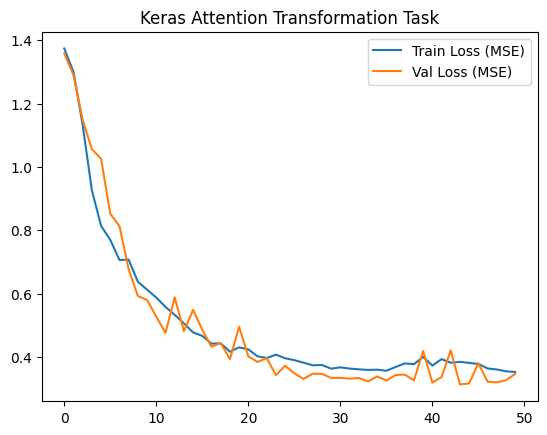

In [57]:
# Plotting the loss to see convergence
plt.plot(history.history['loss'], label='Train Loss (MSE)')
plt.plot(history.history['val_loss'], label='Val Loss (MSE)')
plt.title('Keras Attention Transformation Task')
plt.legend()
plt.show()

---

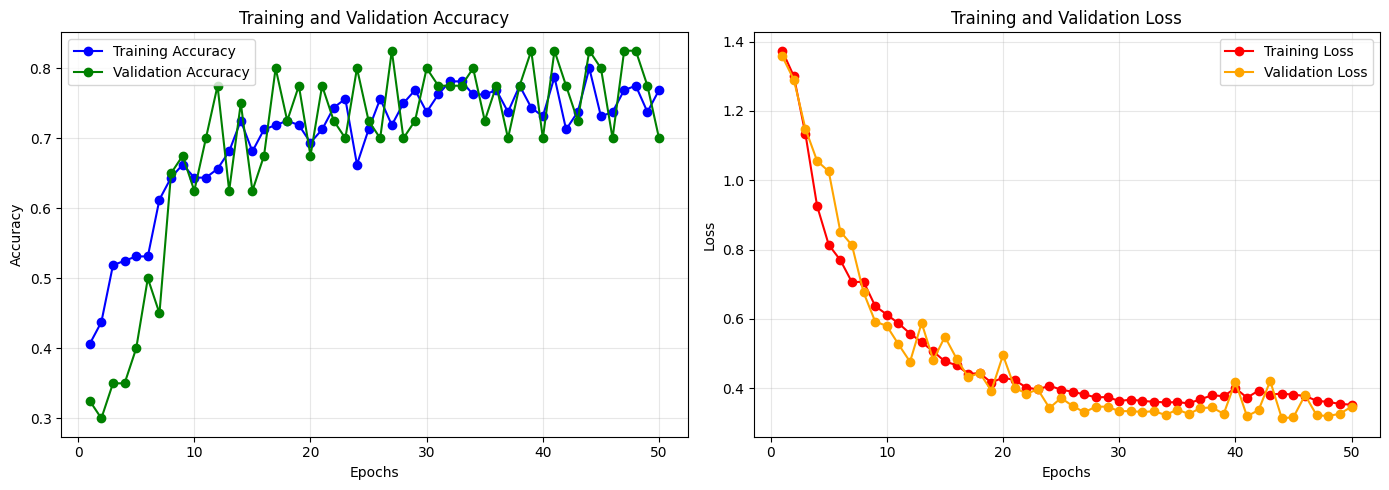

In [62]:
import matplotlib.pyplot as plt

def plot_learning_curves(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs = range(1, len(acc) + 1)

    plt.figure(figsize=(14, 5))

    # Plot Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, 'bo-', label='Training Accuracy')
    plt.plot(epochs, val_acc, 'go-', label='Validation Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True, alpha=0.3)

    # Plot Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, 'ro-', label='Training Loss')
    # FIXED LINE BELOW:
    plt.plot(epochs, val_loss, color='orange', marker='o', label='Validation Loss')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

plot_learning_curves(history)

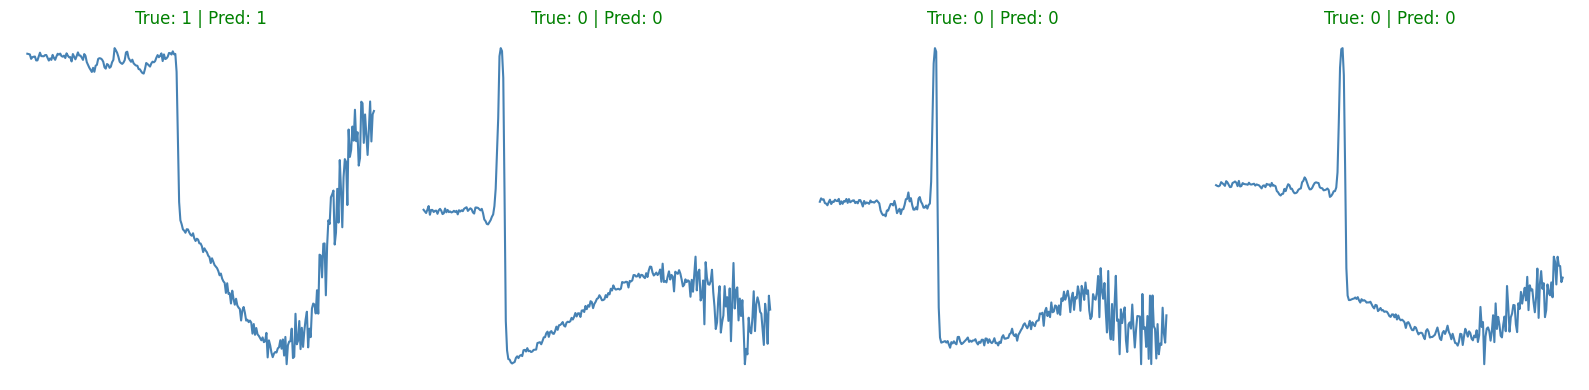

In [61]:
def plot_trace_predictions(model, X, y, num_samples=4):
    # Get predictions for the provided samples
    predictions = model.predict(X[:num_samples], verbose=0)
    pred_labels = np.argmax(predictions, axis=1)
    
    plt.figure(figsize=(16, 4))
    for i in range(num_samples):
        plt.subplot(1, num_samples, i + 1)
        plt.plot(X[i].ravel(), color='steelblue')
        
        # Color the title green if correct, red if wrong
        title_color = 'green' if pred_labels[i] == y[i] else 'red'
        
        plt.title(f"True: {y[i]} | Pred: {pred_labels[i]}", color=title_color)
        plt.axis('off')
    
    plt.tight_layout()
    plt.show()

# Visualize the first few samples from the validation set
plot_trace_predictions(model, X_scaled[-val_size:], y_clean[-val_size:])